[문제 1] 데이터셋 불러오기 및 구조 파악
- 제공된 Gapminder 데이터셋(../data/gapminder.tsv)은 탭(\t) 구분자로 이루어진 TSV 파일입니다. 해당 데이터를 불러와 데이터의 전반적인 구조를 확인하고 특정 조건의 데이터를 추출하는 코드를 작성하세요.  

- 요구사항:
1. pandas 라이브러리를 불러오고, ../data/gapminder.tsv 파일을 데이터프레임 df로 로드하세요 (탭 구분자 지정 필수).  
2. 데이터프레임 df 전체의 행과 열 개수(shape), 열 이름(columns), 그리고 각 열의 데이터 타입(dtypes)을 출력하는 코드를 작성하세요.  
3. df에서 country, continent, year 3개의 열만 선택하여 별도의 데이터프레임 subset으로 추출한 뒤, 상위 5개 행(head())을 출력하세요.

In [11]:
import pandas as pd
df = pd.read_csv('../data/gapminder.tsv', sep='\t')
print(df)

          country continent  year  lifeExp       pop   gdpPercap
0     Afghanistan      Asia  1952   28.801   8425333  779.445314
1     Afghanistan      Asia  1957   30.332   9240934  820.853030
2     Afghanistan      Asia  1962   31.997  10267083  853.100710
3     Afghanistan      Asia  1967   34.020  11537966  836.197138
4     Afghanistan      Asia  1972   36.088  13079460  739.981106
...           ...       ...   ...      ...       ...         ...
1699     Zimbabwe    Africa  1987   62.351   9216418  706.157306
1700     Zimbabwe    Africa  1992   60.377  10704340  693.420786
1701     Zimbabwe    Africa  1997   46.809  11404948  792.449960
1702     Zimbabwe    Africa  2002   39.989  11926563  672.038623
1703     Zimbabwe    Africa  2007   43.487  12311143  469.709298

[1704 rows x 6 columns]


In [19]:
print(df.shape)
print(df.columns)
print(df.dtypes)

(1704, 6)
Index(['country', 'continent', 'year', 'lifeExp', 'pop', 'gdpPercap'], dtype='str')
country          str
continent        str
year           int64
lifeExp      float64
pop            int64
gdpPercap    float64
dtype: object


In [20]:
subset = df[['country', 'continent', 'year']]
print(subset)

          country continent  year
0     Afghanistan      Asia  1952
1     Afghanistan      Asia  1957
2     Afghanistan      Asia  1962
3     Afghanistan      Asia  1967
4     Afghanistan      Asia  1972
...           ...       ...   ...
1699     Zimbabwe    Africa  1987
1700     Zimbabwe    Africa  1992
1701     Zimbabwe    Africa  1997
1702     Zimbabwe    Africa  2002
1703     Zimbabwe    Africa  2007

[1704 rows x 3 columns]


In [21]:
print(subset.head())

       country continent  year
0  Afghanistan      Asia  1952
1  Afghanistan      Asia  1957
2  Afghanistan      Asia  1962
3  Afghanistan      Asia  1967
4  Afghanistan      Asia  1972


[문제 2] 데이터 추출 및 그룹별 기초 통계 계산
- 불러온 데이터프레임 df에서 인덱싱/슬라이싱 기능을 활용하여 데이터를 추출하고, 그룹화(groupby)를 통해 기초 통계량을 집계하세요.  

- 요구사항:
1. iloc 또는 loc를 활용하여 43번째 행(인덱스 번호 42)의 country 열 데이터를 추출하여 출력하세요.  
2. year 별로 그룹화(groupby)하여 lifeExp(기대 수명)의 평균을 구하고 그 결과를 출력하세요.  
3. year와 continent 2개 열을 기준으로 동시 그룹화하여 lifeExp와 gdpPercap의 평균값을 계산한 데이터프레임 multi_group을 생성하세요. 생성된 데이터프레임에 reset_index()를 적용하여 인덱스를 재설정한 결과를 출력하세요.  

In [23]:
df.loc[42]

country           Angola
continent         Africa
year                1982
lifeExp           39.942
pop              7016384
gdpPercap    2756.953672
Name: 42, dtype: object

In [29]:
year_lifeEXP=df.groupby('year')['lifeExp'].mean()
print(year_lifeEXP)

year
1952    49.057620
1957    51.507401
1962    53.609249
1967    55.678290
1972    57.647386
1977    59.570157
1982    61.533197
1987    63.212613
1992    64.160338
1997    65.014676
2002    65.694923
2007    67.007423
Name: lifeExp, dtype: float64


In [33]:
multi_group = df.groupby(['year', 'continent'])[['lifeExp', 'gdpPercap']].mean()
print(multi_group)

                  lifeExp     gdpPercap
year continent                         
1952 Africa     39.135500   1252.572466
     Americas   53.279840   4079.062552
     Asia       46.314394   5195.484004
     Europe     64.408500   5661.057435
     Oceania    69.255000  10298.085650
1957 Africa     41.266346   1385.236062
     Americas   55.960280   4616.043733
     Asia       49.318544   5787.732940
     Europe     66.703067   6963.012816
     Oceania    70.295000  11598.522455
1962 Africa     43.319442   1598.078825
     Americas   58.398760   4901.541870
     Asia       51.563223   5729.369625
     Europe     68.539233   8365.486814
     Oceania    71.085000  12696.452430
1967 Africa     45.334538   2050.363801
     Americas   60.410920   5668.253496
     Asia       54.663640   5971.173374
     Europe     69.737600  10143.823757
     Oceania    71.310000  14495.021790
1972 Africa     47.450942   2339.615674
     Americas   62.394920   6491.334139
     Asia       57.319269   8187.468699


In [34]:
multi_group = multi_group.reset_index()
print(multi_group)

    year continent    lifeExp     gdpPercap
0   1952    Africa  39.135500   1252.572466
1   1952  Americas  53.279840   4079.062552
2   1952      Asia  46.314394   5195.484004
3   1952    Europe  64.408500   5661.057435
4   1952   Oceania  69.255000  10298.085650
5   1957    Africa  41.266346   1385.236062
6   1957  Americas  55.960280   4616.043733
7   1957      Asia  49.318544   5787.732940
8   1957    Europe  66.703067   6963.012816
9   1957   Oceania  70.295000  11598.522455
10  1962    Africa  43.319442   1598.078825
11  1962  Americas  58.398760   4901.541870
12  1962      Asia  51.563223   5729.369625
13  1962    Europe  68.539233   8365.486814
14  1962   Oceania  71.085000  12696.452430
15  1967    Africa  45.334538   2050.363801
16  1967  Americas  60.410920   5668.253496
17  1967      Asia  54.663640   5971.173374
18  1967    Europe  69.737600  10143.823757
19  1967   Oceania  71.310000  14495.021790
20  1972    Africa  47.450942   2339.615674
21  1972  Americas  62.394920   

[문제 3] 데이터 생성, 날짜 연산 및 파일 저장
- 과학자 정보 데이터셋(../data/scientists.csv)을 활용하여 날짜 데이터 타입 변환 및 나이 연산을 수행하고, 처리된 결과를 다양한 파일 형식으로 저장하는 코드를 작성하세요.  
- 요구사항:
    1. ../data/scientists.csv 파일을 읽어와 scientists 데이터프레임에 저장하세요.  
    2. Born 열과 Died 열의 문자열 데이터를 pd.to_datetime() 함수를 사용해 datetime 타입으로 변환한 후, 각각 born_dt와 died_dt 열로 추가하세요.  
    3. died_dt - born_dt 연산을 통해 과학자별 생존 기간을 계산하여 age_days 열을 생성하세요.  
    4. 생존 기간 연산이 완료된 데이터프레임을 인덱스를 제외하고(index=False) ../output/scientists_processed.csv 파일로 저장하는 코드를 작성하세요.  

In [2]:
import pandas as pd
import os

scientists = pd.read_csv('../data/scientists.csv')
print(scientists)

                   Name        Born        Died  Age          Occupation
0     Rosaline Franklin  1920-07-25  1958-04-16   37             Chemist
1        William Gosset  1876-06-13  1937-10-16   61        Statistician
2  Florence Nightingale  1820-05-12  1910-08-13   90               Nurse
3           Marie Curie  1867-11-07  1934-07-04   66             Chemist
4         Rachel Carson  1907-05-27  1964-04-14   56           Biologist
5             John Snow  1813-03-15  1858-06-16   45           Physician
6           Alan Turing  1912-06-23  1954-06-07   41  Computer Scientist
7          Johann Gauss  1777-04-30  1855-02-23   77       Mathematician


In [3]:
scientists['born_dt'] = pd.to_datetime(scientists['Born'])
scientists['died_dt'] = pd.to_datetime(scientists['Died'])

In [40]:
scientists['age_days'] = scientists['died_dt'] - scientists['born_dt']

os.makedirs('../output', exist_ok=True)

In [4]:
scientists.to_csv('./output/scientists_processed.csv', index=False)

In [38]:
print(scientists.head())

                   Name        Born        Died  Age    Occupation    born_dt  \
0     Rosaline Franklin  1920-07-25  1958-04-16   37       Chemist 1920-07-25   
1        William Gosset  1876-06-13  1937-10-16   61  Statistician 1876-06-13   
2  Florence Nightingale  1820-05-12  1910-08-13   90         Nurse 1820-05-12   
3           Marie Curie  1867-11-07  1934-07-04   66       Chemist 1867-11-07   
4         Rachel Carson  1907-05-27  1964-04-14   56     Biologist 1907-05-27   

     died_dt  
0 1958-04-16  
1 1937-10-16  
2 1910-08-13  
3 1934-07-04  
4 1964-04-14  


[문제 4] 복합 열 이름 분할 및 국가별 감염 사례 집계 시각화

- `country_timeseries.csv` 데이터는 에볼라 바이러스의 감염 사례 및 사망자 수가 국가와 함께 열 이름(예: `Cases_Guinea`, `Deaths_Guinea`)에 합성되어 저장되어 있습니다.

- 요구사항:
1. `Date`와 `Day` 열을 제외한 나머지 열들을 `variable`과 `value`로 `melt`하세요.
2. `variable` 열의 문자열을 `'_'` 기준으로 분할(`str.split(..., expand=True)`)하여, 감염/사망 상태를 나타내는 `status` 열과 국가명을 나타내는 `country` 열로 분리한 뒤 기존 데이터프레임에 추가하세요.
3. `status`가 `'Cases'`(감염 사례)인 데이터 중 결측치(`NaN`)를 제외하고, 국가(`country`)별 총 감염 사례 수 합계를 구해 내림차순으로 정렬된 결과를 출력하세요.
4. 상위 3개 국가의 총 감염 사례 수를 비교하는 **막대그래프(Bar Chart)**를 시각화하세요.


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


ebola = pd.read_csv('../data/country_timeseries.csv')

print(ebola)

           Date  Day  Cases_Guinea  Cases_Liberia  Cases_SierraLeone  \
0      1/5/2015  289        2776.0            NaN            10030.0   
1      1/4/2015  288        2775.0            NaN             9780.0   
2      1/3/2015  287        2769.0         8166.0             9722.0   
3      1/2/2015  286           NaN         8157.0                NaN   
4    12/31/2014  284        2730.0         8115.0             9633.0   
..          ...  ...           ...            ...                ...   
117   3/27/2014    5         103.0            8.0                6.0   
118   3/26/2014    4          86.0            NaN                NaN   
119   3/25/2014    3          86.0            NaN                NaN   
120   3/24/2014    2          86.0            NaN                NaN   
121   3/22/2014    0          49.0            NaN                NaN   

     Cases_Nigeria  Cases_Senegal  Cases_UnitedStates  Cases_Spain  \
0              NaN            NaN                 NaN          Na

In [8]:
ebola_melt = ebola.melt(id_vars=['Date', 'Day'])
print(ebola_melt)

            Date  Day      variable   value
0       1/5/2015  289  Cases_Guinea  2776.0
1       1/4/2015  288  Cases_Guinea  2775.0
2       1/3/2015  287  Cases_Guinea  2769.0
3       1/2/2015  286  Cases_Guinea     NaN
4     12/31/2014  284  Cases_Guinea  2730.0
...          ...  ...           ...     ...
1947   3/27/2014    5   Deaths_Mali     NaN
1948   3/26/2014    4   Deaths_Mali     NaN
1949   3/25/2014    3   Deaths_Mali     NaN
1950   3/24/2014    2   Deaths_Mali     NaN
1951   3/22/2014    0   Deaths_Mali     NaN

[1952 rows x 4 columns]


In [9]:
status_country = ebola_melt['variable'].str.split('_', expand=True)
ebola_melt[['status', 'country']] = status_country

In [46]:
print(ebola_melt.head())

         Date  Day      variable   value status country
0    1/5/2015  289  Cases_Guinea  2776.0  Cases  Guinea
1    1/4/2015  288  Cases_Guinea  2775.0  Cases  Guinea
2    1/3/2015  287  Cases_Guinea  2769.0  Cases  Guinea
3    1/2/2015  286  Cases_Guinea     NaN  Cases  Guinea
4  12/31/2014  284  Cases_Guinea  2730.0  Cases  Guinea


In [10]:
cases_by_country = (
    ebola_melt[ebola_melt['status'] == 'Cases']
    .dropna(subset=['value'])
    .groupby('country')['value']
    .sum()
    .sort_values(ascending=False)
)

print("=== 국가별 총 감염 사례 수 합계 (내림차순) ===")
print(cases_by_country)

=== 국가별 총 감염 사례 수 합계 (내림차순) ===
country
SierraLeone     211181.0
Liberia         193833.0
Guinea           84729.0
Nigeria            636.0
UnitedStates        59.0
Mali                42.0
Senegal             27.0
Spain               16.0
Name: value, dtype: float64


C:\Users\PC\AppData\Local\Temp\ipykernel_29132\3081345811.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top3_cases.index, y=top3_cases.values, palette='Blues_r')


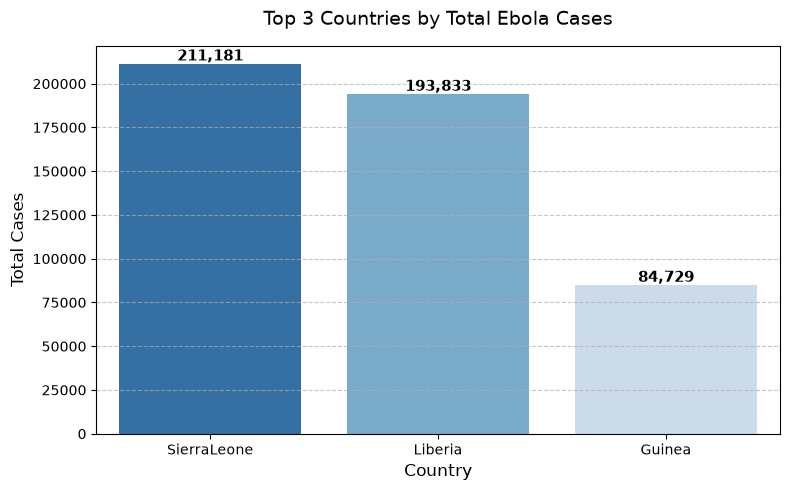

In [11]:
top3_cases = cases_by_country.head(3)

plt.figure(figsize=(8, 5))
sns.barplot(x=top3_cases.index, y=top3_cases.values, palette='Blues_r')

plt.title('Top 3 Countries by Total Ebola Cases', fontsize=14, pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Total Cases', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)


for i, v in enumerate(top3_cases.values):
    plt.text(i, v, f'{int(v):,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()